# Phishing Website Detection System

## Step 1: Import libraries and load dataset

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

os.makedirs("output", exist_ok=True)

df = pd.read_csv("phishing.csv")

print(df.shape)
print(df.head())
print(df.info())

# Target: class (-1 = Phishing, 1 = Legitimate)
print("\nClass counts:")
print(df["class"].value_counts())

(11054, 32)
   Index  UsingIP  LongURL  ShortURL  Symbol@  Redirecting//  PrefixSuffix-  \
0      0        1        1         1        1              1             -1   
1      1        1        0         1        1              1             -1   
2      2        1        0         1        1              1             -1   
3      3        1        0        -1        1              1             -1   
4      4       -1        0        -1        1             -1             -1   

   SubDomains  HTTPS  DomainRegLen  ...  UsingPopupWindow  IframeRedirection  \
0           0      1            -1  ...                 1                  1   
1          -1     -1            -1  ...                 1                  1   
2          -1     -1             1  ...                 1                  1   
3           1      1            -1  ...                -1                  1   
4           1      1            -1  ...                 1                  1   

   AgeofDomain  DNSRecording  We

## Step 2: Preprocess data (missing values, duplicates, unwanted columns)

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicates (excluding Index):", df.drop(columns=["Index"]).duplicated().sum())

# Index is only a row number, so it is not a useful feature
df = df.drop(columns=["Index"])
df = df.dropna()

# Remove duplicate rows. Identical rows in both train and test sets would
# leak information and give over-optimistic scores.
df = df.drop_duplicates().reset_index(drop=True)

# All features are already numeric (-1, 0, 1), so no encoding is needed
print("Clean shape:", df.shape)
df.to_csv("output/cleaned_data.csv", index=False)

Missing values: 0
Duplicates (excluding Index): 5205
Clean shape: (5849, 31)


## Step 3: Analyze data (EDA)

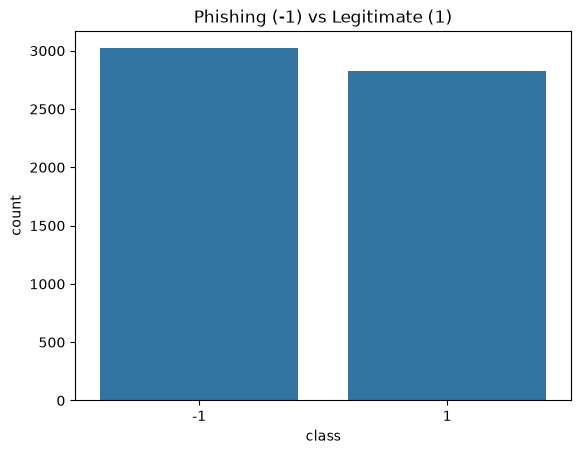

class
-1    51.62
 1    48.38
Name: proportion, dtype: float64


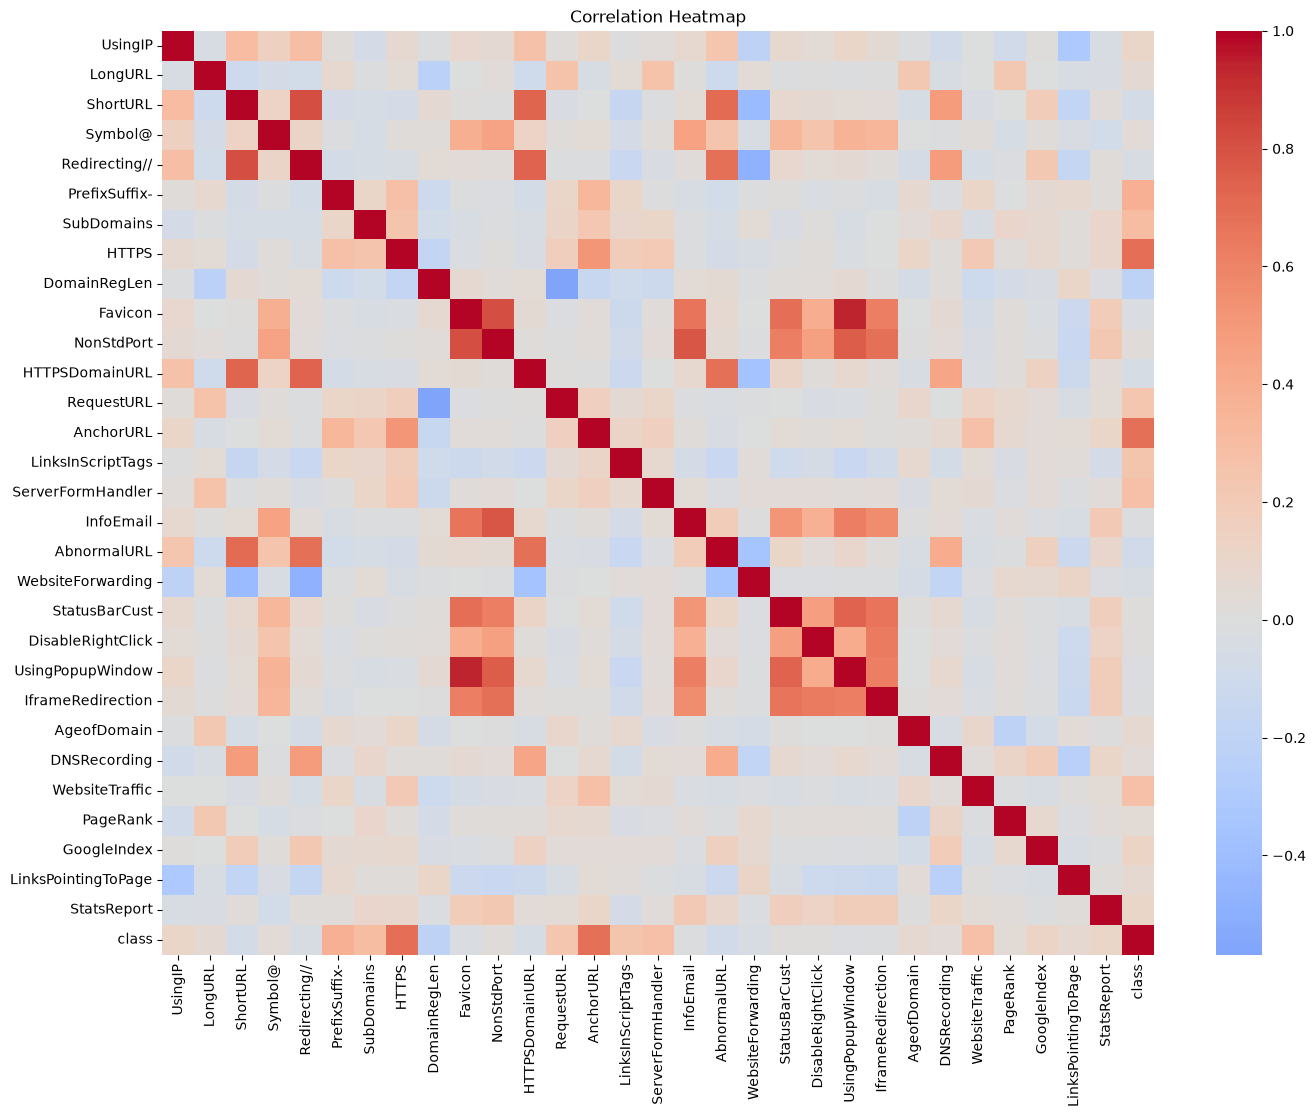

HTTPS                  0.693228
AnchorURL              0.679125
PrefixSuffix-          0.381134
SubDomains             0.296214
WebsiteTraffic         0.281709
ServerFormHandler      0.281131
LinksInScriptTags      0.243864
RequestURL             0.237778
GoogleIndex            0.118217
StatsReport            0.108486
UsingIP                0.104952
LinksPointingToPage    0.068463
AgeofDomain            0.062800
LongURL                0.058228
PageRank               0.048140
Symbol@                0.034757
DNSRecording           0.033204
NonStdPort             0.014201
StatusBarCust          0.012790
DisableRightClick      0.009286
InfoEmail             -0.008014
IframeRedirection     -0.011756
UsingPopupWindow      -0.022455
Favicon               -0.025457
Redirecting//         -0.036693
WebsiteForwarding     -0.037462
HTTPSDomainURL        -0.051412
ShortURL              -0.076166
AbnormalURL           -0.090043
DomainRegLen          -0.218623
Name: class, dtype: float64


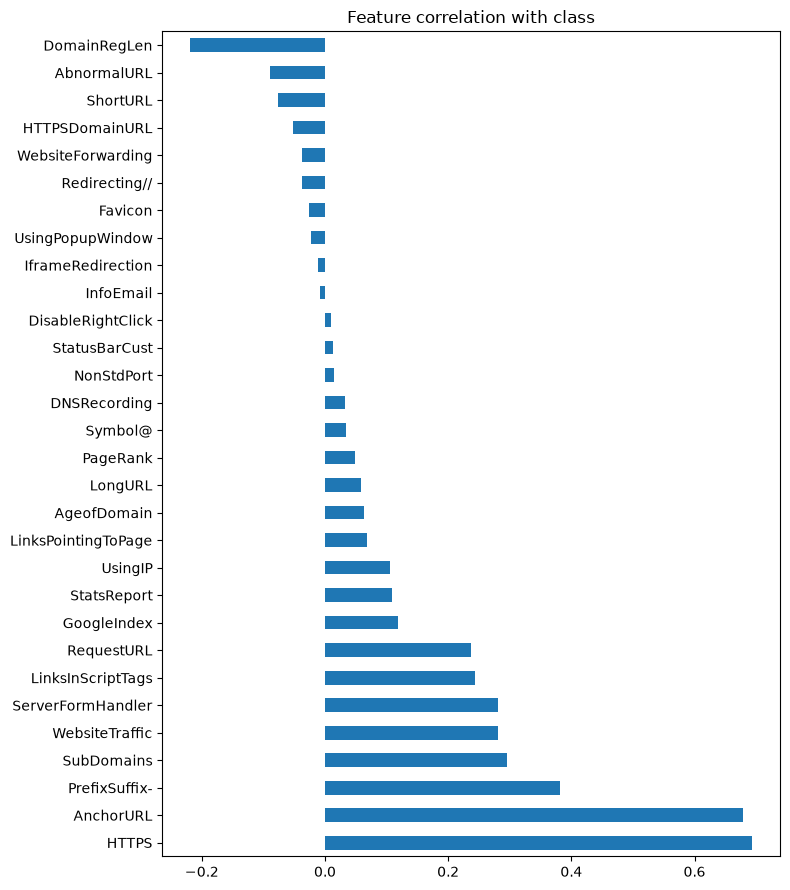

In [4]:
sns.countplot(x="class", data=df)
plt.title("Phishing (-1) vs Legitimate (1)")
plt.savefig("output/class_count.png")
plt.show()

print((df["class"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.savefig("output/correlation_heatmap.png")
plt.show()

corr = df.corr()["class"].drop("class").sort_values(ascending=False)
print(corr)

corr.plot(kind="barh", figsize=(8, 9), title="Feature correlation with class")
plt.tight_layout()
plt.savefig("output/feature_correlation.png")
plt.show()

## Step 4: Split the data

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("class", axis=1)
y = df["class"]
features = list(X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaler is used only for Logistic Regression
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (4679, 30)
Testing set: (1170, 30)


## Step 5: Train three classification models

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_s, y_train)

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

print("All three models trained")

All three models trained


## Step 6: Evaluate and compare the models

Logistic Regression
              precision    recall  f1-score   support

    Phishing       0.93      0.90      0.91       604
  Legitimate       0.90      0.92      0.91       566

    accuracy                           0.91      1170
   macro avg       0.91      0.91      0.91      1170
weighted avg       0.91      0.91      0.91      1170



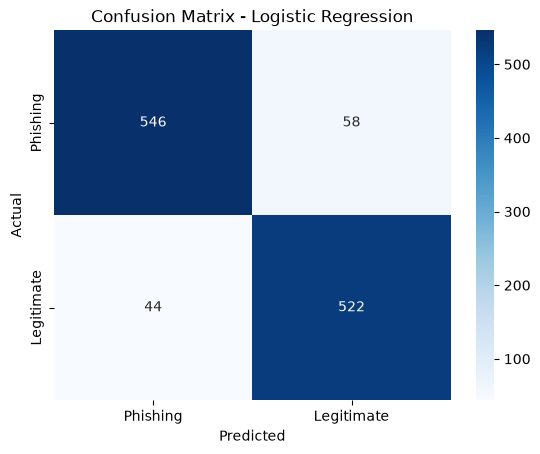

Decision Tree
              precision    recall  f1-score   support

    Phishing       0.91      0.93      0.92       604
  Legitimate       0.92      0.90      0.91       566

    accuracy                           0.92      1170
   macro avg       0.92      0.92      0.92      1170
weighted avg       0.92      0.92      0.92      1170



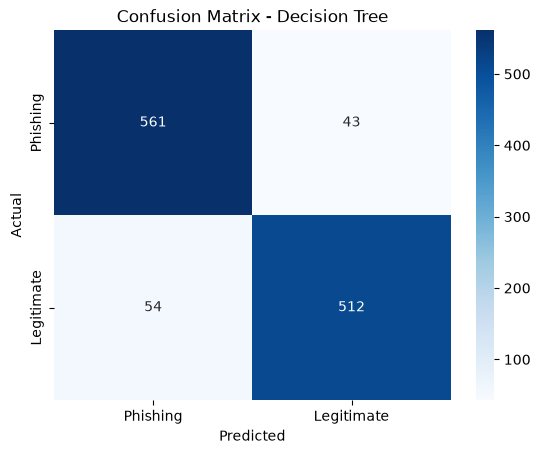

Random Forest
              precision    recall  f1-score   support

    Phishing       0.95      0.94      0.95       604
  Legitimate       0.94      0.95      0.94       566

    accuracy                           0.95      1170
   macro avg       0.95      0.95      0.95      1170
weighted avg       0.95      0.95      0.95      1170



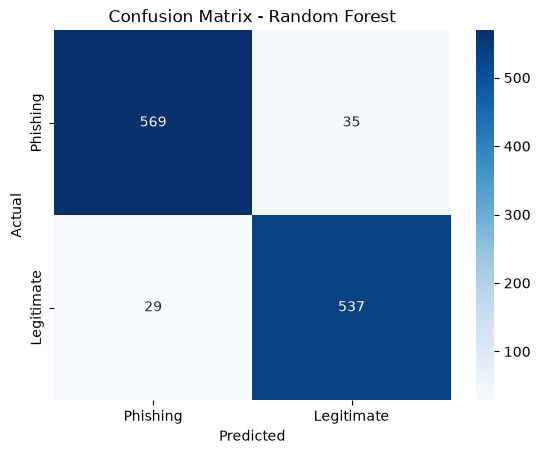

              Model  Accuracy  Precision  Recall (Phishing)  F1-score
Logistic Regression    0.9128     0.9254             0.9040    0.9146
      Decision Tree    0.9171     0.9122             0.9288    0.9204
      Random Forest    0.9453     0.9515             0.9421    0.9468


In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

models = {
    "Logistic Regression": (log_model, X_test_s),
    "Decision Tree": (tree_model, X_test),
    "Random Forest": (rf_model, X_test),
}

rows = []
for name, (model, Xt) in models.items():
    pred = model.predict(Xt)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=-1),
        "Recall (Phishing)": recall_score(y_test, pred, pos_label=-1),
        "F1-score": f1_score(y_test, pred, pos_label=-1),
    })
    print(name)
    print(classification_report(y_test, pred, target_names=["Phishing", "Legitimate"]))

    sns.heatmap(confusion_matrix(y_test, pred, labels=[-1, 1]), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Phishing", "Legitimate"], yticklabels=["Phishing", "Legitimate"])
    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.savefig("output/cm_" + name.replace(" ", "_").lower() + ".png")
    plt.show()

comparison = pd.DataFrame(rows).round(4)
print(comparison.to_string(index=False))
comparison.to_csv("output/model_comparison.csv", index=False)

## Step 7: Cross-validation (5-fold)

In [8]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model, Xtr in [("Logistic Regression", log_model, X_train_s),
                         ("Decision Tree", tree_model, X_train),
                         ("Random Forest", rf_model, X_train)]:
    scores = cross_val_score(model, Xtr, y_train, cv=cv5, scoring="accuracy")
    print(name)
    print("  Fold scores:", np.round(scores, 4))
    print("  Average    :", round(scores.mean(), 4))

Logistic Regression
  Fold scores: [0.9444 0.9199 0.9188 0.9167 0.9112]
  Average    : 0.9222
Decision Tree
  Fold scores: [0.9284 0.9188 0.9188 0.9156 0.9187]
  Average    : 0.9201
Random Forest
  Fold scores: [0.9573 0.9412 0.937  0.9359 0.9422]
  Average    : 0.9427


## Step 8: Hyperparameter tuning (GridSearchCV)

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

# Phishing recall is the main score because a missed phishing site is risky
phish_recall = make_scorer(recall_score, pos_label=-1)

grid_log = GridSearchCV(LogisticRegression(max_iter=1000),
                        {"C": [0.01, 0.1, 1, 10, 100]},
                        cv=cv5, scoring=phish_recall)
grid_log.fit(X_train_s, y_train)

grid_tree = GridSearchCV(DecisionTreeClassifier(random_state=42),
                         {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 5, 10]},
                         cv=cv5, scoring=phish_recall)
grid_tree.fit(X_train, y_train)

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                       {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
                       cv=cv5, scoring=phish_recall)
grid_rf.fit(X_train, y_train)

for name, g in [("Logistic Regression", grid_log), ("Decision Tree", grid_tree), ("Random Forest", grid_rf)]:
    print(name, "| best params:", g.best_params_, "| CV phishing recall:", round(g.best_score_, 4))

Logistic Regression | best params: {'C': 1} | CV phishing recall: 0.9159
Decision Tree | best params: {'max_depth': 10, 'min_samples_split': 5} | CV phishing recall: 0.9342
Random Forest | best params: {'max_depth': 20, 'n_estimators': 100} | CV phishing recall: 0.94


## Step 9: Select the best model and test it

Selected model: Random Forest
Accuracy : 0.9436
Precision: 0.9513
Recall   : 0.9387
F1-score : 0.945
              precision    recall  f1-score   support

    Phishing       0.95      0.94      0.94       604
  Legitimate       0.94      0.95      0.94       566

    accuracy                           0.94      1170
   macro avg       0.94      0.94      0.94      1170
weighted avg       0.94      0.94      0.94      1170



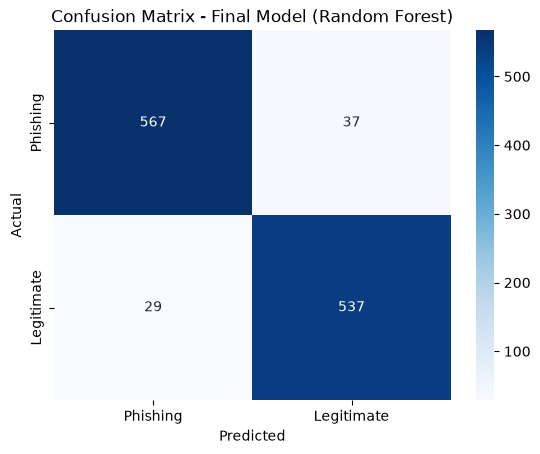

In [10]:
grids = {"Logistic Regression": grid_log, "Decision Tree": grid_tree, "Random Forest": grid_rf}
best_name = max(grids, key=lambda k: grids[k].best_score_)
best_model = grids[best_name].best_estimator_
Xt_best = X_test_s if best_name == "Logistic Regression" else X_test

print("Selected model:", best_name)

best_pred = best_model.predict(Xt_best)
print("Accuracy :", round(accuracy_score(y_test, best_pred), 4))
print("Precision:", round(precision_score(y_test, best_pred, pos_label=-1), 4))
print("Recall   :", round(recall_score(y_test, best_pred, pos_label=-1), 4))
print("F1-score :", round(f1_score(y_test, best_pred, pos_label=-1), 4))
print(classification_report(y_test, best_pred, target_names=["Phishing", "Legitimate"]))

sns.heatmap(confusion_matrix(y_test, best_pred, labels=[-1, 1]), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Phishing", "Legitimate"], yticklabels=["Phishing", "Legitimate"])
plt.title("Confusion Matrix - Final Model (" + best_name + ")")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("output/confusion_matrix_final.png")
plt.show()

## Step 10: Classify new, unseen website data

In [11]:
import re
from urllib.parse import urlparse
from sklearn.ensemble import RandomForestClassifier

# ---------- URL feature extraction (10 URL-based features) ----------
URL_FEATURES = ["UsingIP", "LongURL", "ShortURL", "Symbol@", "Redirecting//",
                "PrefixSuffix-", "SubDomains", "HTTPS", "NonStdPort", "HTTPSDomainURL"]
SHORTENERS = r"bit\.ly|goo\.gl|tinyurl|t\.co|ow\.ly|is\.gd|buff\.ly|adf\.ly|tr\.im|cli\.gs"

def url_to_features(url):
    if not re.match(r"^\w+://", url):
        url = "http://" + url
    p = urlparse(url)
    host = p.hostname or ""
    dots = host.replace("www.", "", 1).count(".")
    return {
        "UsingIP": -1 if re.fullmatch(r"(\d{1,3}\.){3}\d{1,3}", host) else 1,
        "LongURL": 1 if len(url) < 54 else (0 if len(url) <= 75 else -1),
        "ShortURL": -1 if re.search(SHORTENERS, host) else 1,
        "Symbol@": -1 if "@" in url else 1,
        "Redirecting//": -1 if url.rfind("//") > 7 else 1,
        "PrefixSuffix-": -1 if "-" in host else 1,
        "SubDomains": 1 if dots <= 1 else (0 if dots == 2 else -1),
        "HTTPS": 1 if p.scheme == "https" else -1,
        "NonStdPort": -1 if p.port not in (None, 80, 443) else 1,
        "HTTPSDomainURL": -1 if "https" in host else 1,
    }

# Model trained only on the URL-based features
url_model = RandomForestClassifier(random_state=42, n_jobs=-1)
url_model.fit(X_train[URL_FEATURES], y_train)
joblib.dump(url_model, "output/url_model.pkl")

# ---------- Prediction functions ----------
def label(result):
    return "Potentially Phishing" if result == -1 else "Likely Legitimate"

def predict_website(site):
    """site: dictionary with a value (-1, 0 or 1) for every feature column"""
    s = pd.DataFrame([site])[features]
    if best_name == "Logistic Regression":
        s = scaler.transform(s)
    return label(best_model.predict(s)[0])

def predict_url(url):
    row = pd.DataFrame([url_to_features(url)])[URL_FEATURES]
    return label(url_model.predict(row)[0])

# ---------- User input ----------
def classify_new_website():
    print("Phishing Website Detection System")
    print("1 = Enter website URL")
    print("2 = Enter 30 feature values (-1, 0, 1)")
    choice = input("Choose 1 or 2: ").strip()

    if choice == "1":
        url = input("Enter website URL: ").strip()
        print("Prediction:", predict_url(url))
    elif choice == "2":
        values = input("Enter " + str(len(features)) + " values separated by commas: ")
        site = dict(zip(features, [float(v) for v in values.split(",")]))
        print("Prediction:", predict_website(site))
    else:
        print("Invalid choice")

# ---------- Examples ----------
print("Phishing Website Detection System")

# Example 1: real row from the test set
example = X_test.iloc[0].to_dict()
print("Prediction:", predict_website(example), "| Actual:", "Phishing" if y_test.iloc[0] == -1 else "Legitimate")

# Example 2: your own 30 feature values
new_site = {f: 1 for f in features}
print("Prediction:", predict_website(new_site))

# Example 3: URL input
print("Prediction:", predict_url("https://www.google.com"))
print("Prediction:", predict_url("http://secure-paypal-login.example-verify.com/account/update/confirm?id=12345"))

# Remove the # to enter your own input
 # classify_new_website()

Phishing Website Detection System
Prediction: Potentially Phishing | Actual: Phishing
Prediction: Likely Legitimate
Prediction: Likely Legitimate
Prediction: Potentially Phishing


In [15]:
classify_new_website()

Phishing Website Detection System
1 = Enter website URL
2 = Enter 30 feature values (-1, 0, 1)
Prediction: Potentially Phishing


## Step 11: Save the model and build a simple interface

In [13]:
joblib.dump({"model": best_model, "scaler": scaler, "features": features, "name": best_name},
            "output/phishing_model.pkl")
print("Model and preprocessing saved in the output folder")

Model and preprocessing saved in the output folder


In [14]:
# Command-line interface (reuses the saved model, no retraining)
def run_cli():
    bundle = joblib.load("output/phishing_model.pkl")
    values = input("Enter " + str(len(bundle["features"])) + " feature values (-1, 0, 1) separated by commas: ")
    row = pd.DataFrame([[float(v) for v in values.split(",")]], columns=bundle["features"])
    if bundle["name"] == "Logistic Regression":
        row = bundle["scaler"].transform(row)
    result = bundle["model"].predict(row)[0]
    print("Prediction:", "Potentially Phishing" if result == -1 else "Likely Legitimate")

# run_cli()   # remove the # to try it